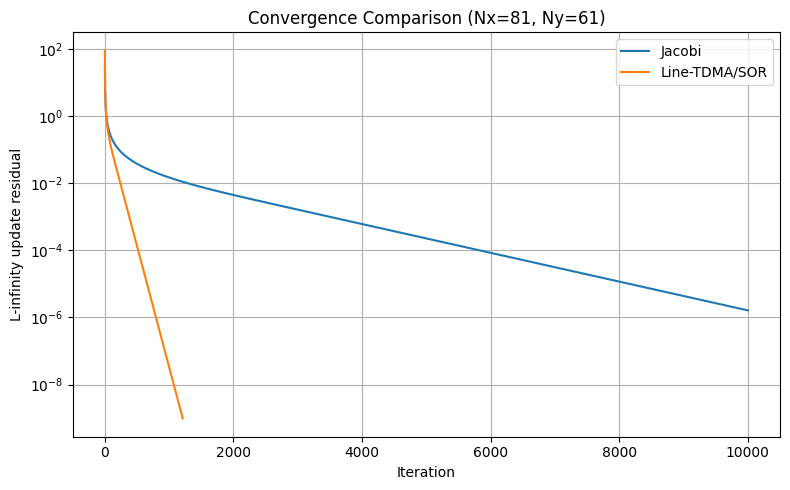

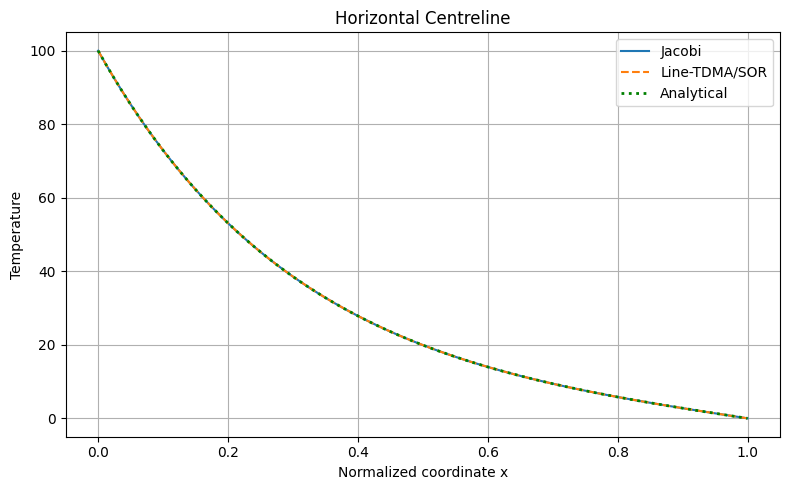

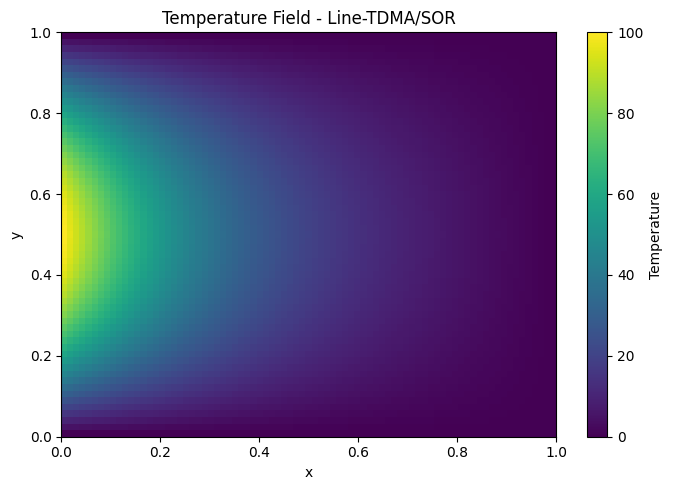


RESULTS
------------------------------------------------------------
Grid size                 : 81 x 61
Source temperature        : 100.0
Maximum iterations        : 10000
Convergence tolerance     : 1.0e-09
SOR relaxation factor     : 1.5
Jacobi iterations         : 10000
Line-TDMA/SOR iterations  : 1211
Jacobi final update       : 1.621069e-06
Line-TDMA final update    : 9.845671e-10
Jacobi relative L2 error  : 7.893996e-05
Line-TDMA relative L2 err : 1.055691e-04


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# EXPERIMENT 6: TWO-DIMENSIONAL STEADY HEAT CONDUCTION
# Jacobi vs Line-TDMA/SOR
# =====================================================

Lx, Ly = 1.0, 1.0
Nx, Ny = 81, 61
T_source = 100.0
max_iter = 10000
tol = 1e-9
omega = 1.5

x = np.linspace(0, Lx, Nx)
y = np.linspace(0, Ly, Ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Boundary conditions:
# Left: T = 100 sin(pi*y/Ly)
# Right, top and bottom: T = 0

def set_boundaries(T):
    T[:, 0] = T_source * np.sin(np.pi * y / Ly)
    T[:, -1] = 0.0
    T[0, :] = 0.0
    T[-1, :] = 0.0
    T[0, 0] = 0.0
    T[-1, 0] = 0.0
    return T

# Analytical solution for comparison
def analytical_solution():
    X, Y = np.meshgrid(x, y)
    T = T_source * np.sin(np.pi * Y / Ly) * (
        np.sinh(np.pi * (Lx - X) / Ly)
        / np.sinh(np.pi * Lx / Ly)
    )
    return T

T_exact = analytical_solution()

# -----------------------------------------------------
# 1. JACOBI SOLVER
# -----------------------------------------------------
def solve_jacobi():
    T = np.zeros((Ny, Nx))
    set_boundaries(T)
    residuals = []

    ax = 1.0 / dx**2
    ay = 1.0 / dy**2
    denom = 2.0 * (ax + ay)

    for it in range(max_iter):
        old = T.copy()
        T[1:-1, 1:-1] = (
            ax * (old[1:-1, 2:] + old[1:-1, :-2])
            + ay * (old[2:, 1:-1] + old[:-2, 1:-1])
        ) / denom

        set_boundaries(T)

        residual = np.max(np.abs(T - old))
        residuals.append(residual)

        if residual < tol:
            break

    return T, np.array(residuals), it + 1

# -----------------------------------------------------
# 2. LINE-TDMA WITH SOR RELAXATION
# Solve each horizontal line using the Thomas algorithm
# -----------------------------------------------------
def thomas(a, b, c, d):
    n = len(b)
    cp = np.zeros(n)
    dp = np.zeros(n)

    cp[0] = c[0] / b[0]
    dp[0] = d[0] / b[0]

    for k in range(1, n):
        den = b[k] - a[k] * cp[k-1]
        cp[k] = c[k] / den if k < n-1 else 0.0
        dp[k] = (d[k] - a[k] * dp[k-1]) / den

    sol = np.zeros(n)
    sol[-1] = dp[-1]

    for k in range(n-2, -1, -1):
        sol[k] = dp[k] - cp[k] * sol[k+1]

    return sol

def solve_line_tdma():
    T = np.zeros((Ny, Nx))
    set_boundaries(T)
    residuals = []

    ni = Nx - 2
    ax = 1.0 / dx**2
    ay = 1.0 / dy**2

    a = np.full(ni, -ax)
    b = np.full(ni, 2.0 * (ax + ay))
    c = np.full(ni, -ax)

    for it in range(max_iter):
        old = T.copy()

        # Sweep through interior horizontal rows
        for j in range(1, Ny-1):
            d = ay * (T[j-1, 1:-1] + T[j+1, 1:-1])

            # Boundary contributions
            d = d.copy()
            d[0] += ax * T[j, 0]
            d[-1] += ax * T[j, -1]

            row_solution = thomas(a, b, c, d)

            T[j, 1:-1] = (
                omega * row_solution
                + (1.0 - omega) * T[j, 1:-1]
            )

        set_boundaries(T)

        residual = np.max(np.abs(T - old))
        residuals.append(residual)

        if residual < tol:
            break

    return T, np.array(residuals), it + 1

# -----------------------------------------------------
# 3. RUN BOTH METHODS
# -----------------------------------------------------
T_jacobi, res_jacobi, iter_jacobi = solve_jacobi()
T_line, res_line, iter_line = solve_line_tdma()

# -----------------------------------------------------
# GRAPH 1: CONVERGENCE COMPARISON
# -----------------------------------------------------
plt.figure(figsize=(8, 5))
plt.semilogy(
    np.arange(1, len(res_jacobi)+1),
    res_jacobi, label="Jacobi"
)
plt.semilogy(
    np.arange(1, len(res_line)+1),
    res_line, label="Line-TDMA/SOR"
)
plt.xlabel("Iteration")
plt.ylabel("L-infinity update residual")
plt.title(f"Convergence Comparison (Nx={Nx}, Ny={Ny})")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# -----------------------------------------------------
# GRAPH 2: HORIZONTAL CENTRELINE
# -----------------------------------------------------
j_mid = Ny // 2

plt.figure(figsize=(8, 5))
plt.plot(x, T_jacobi[j_mid, :], label="Jacobi")
plt.plot(x, T_line[j_mid, :], "--", label="Line-TDMA/SOR")
plt.plot(x, T_exact[j_mid, :], "g:", linewidth=2,
         label="Analytical")
plt.xlabel("Normalized coordinate x")
plt.ylabel("Temperature")
plt.title("Horizontal Centreline")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# -----------------------------------------------------
# GRAPH 3: TEMPERATURE FIELD
# -----------------------------------------------------
plt.figure(figsize=(7, 5))
plt.imshow(
    T_line, origin="lower",
    extent=[0, Lx, 0, Ly],
    aspect="auto", cmap="viridis"
)
plt.colorbar(label="Temperature")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Temperature Field - Line-TDMA/SOR")
plt.tight_layout()
plt.show()

# -----------------------------------------------------
# RESULTS
# -----------------------------------------------------
def relative_l2(T, exact):
    return np.linalg.norm(T - exact) / np.linalg.norm(exact)

print("\nRESULTS")
print("-" * 60)
print(f"Grid size                 : {Nx} x {Ny}")
print(f"Source temperature        : {T_source}")
print(f"Maximum iterations        : {max_iter}")
print(f"Convergence tolerance     : {tol:.1e}")
print(f"SOR relaxation factor     : {omega}")
print(f"Jacobi iterations         : {iter_jacobi}")
print(f"Line-TDMA/SOR iterations  : {iter_line}")
print(f"Jacobi final update       : {res_jacobi[-1]:.6e}")
print(f"Line-TDMA final update    : {res_line[-1]:.6e}")
print(f"Jacobi relative L2 error  : {relative_l2(T_jacobi,T_exact):.6e}")
print(f"Line-TDMA relative L2 err : {relative_l2(T_line,T_exact):.6e}")


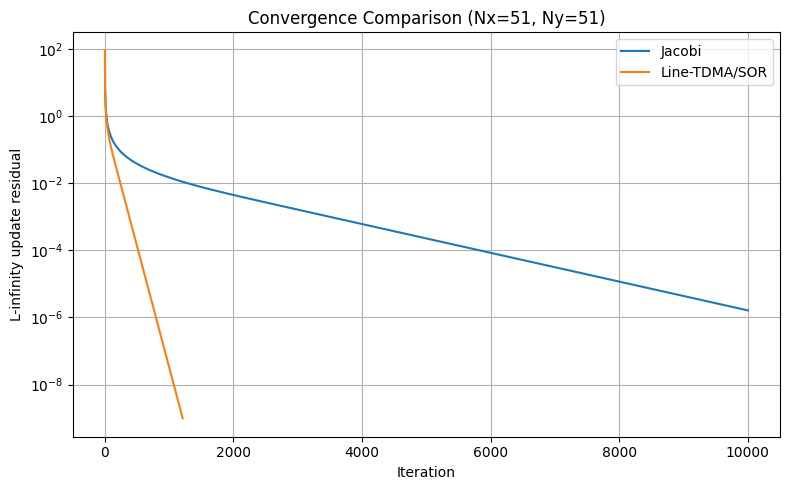

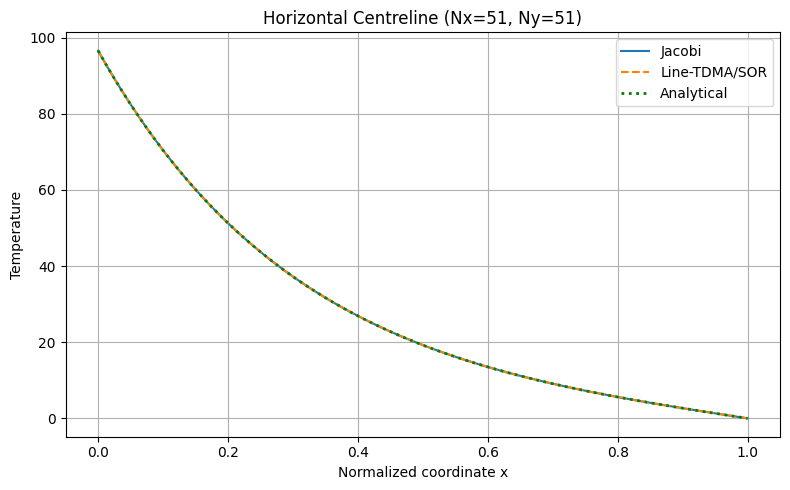

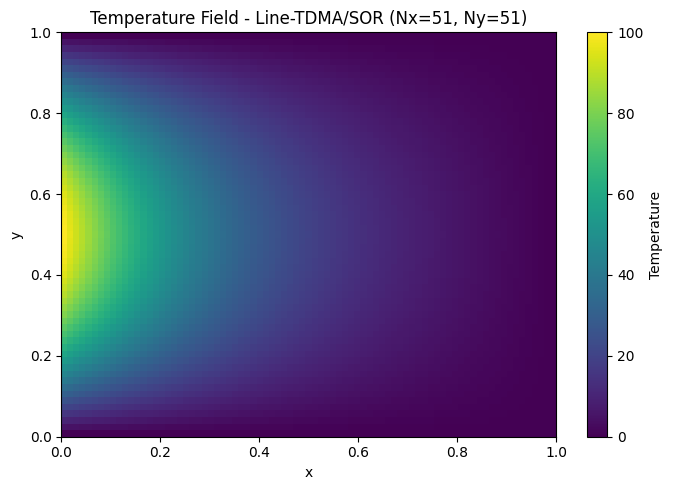

In [5]:

# GRAPHS FOR 51 x 51 GRID
# Requires: T_jacobi, T_line, T_exact, res_jacobi,
# res_line, Nx, Ny, x, y from the solver cell.

import numpy as np
import matplotlib.pyplot as plt

# 1. Convergence comparison
plt.figure(figsize=(8, 5))
plt.semilogy(
    np.arange(1, len(res_jacobi) + 1),
    np.maximum(res_jacobi, 1e-16),
    label="Jacobi"
)
plt.semilogy(
    np.arange(1, len(res_line) + 1),
    np.maximum(res_line, 1e-16),
    label="Line-TDMA/SOR"
)
plt.xlabel("Iteration")
plt.ylabel("L-infinity update residual")
plt.title(f"Convergence Comparison (Nx={Nx}, Ny={Ny})")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# 2. Horizontal centreline comparison
j_mid = Ny // 2

plt.figure(figsize=(8, 5))
plt.plot(x, T_jacobi[j_mid, :], label="Jacobi")
plt.plot(x, T_line[j_mid, :], "--", label="Line-TDMA/SOR")
plt.plot(x, T_exact[j_mid, :], "g:", linewidth=2,
         label="Analytical")
plt.xlabel("Normalized coordinate x")
plt.ylabel("Temperature")
plt.title(f"Horizontal Centreline (Nx={Nx}, Ny={Ny})")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# 3. Temperature field preview
plt.figure(figsize=(7, 5))
plt.imshow(
    T_line,
    origin="lower",
    extent=[0, 1, 0, 1],
    aspect="auto",
    cmap="viridis"
)
plt.colorbar(label="Temperature")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Temperature Field - Line-TDMA/SOR (Nx={Nx}, Ny={Ny})")
plt.tight_layout()
plt.show()
